### Data Source
Data derived from the ICRISAT District Level Database (DLD)
http://data.icrisat.org/dld/index.html
Licensed under CC BY 4.0

---

# India District-Level Rice Yield Forecasting
### From yield history, irrigation, monsoon rainfall, fertilizer and soil

Notebook by: Nawa P.

This project forecasts district-level crop yield in India one season ahead, using publicly available ICRISAT data. The approach can be extended to Thailand using data from the Land Development Department (กรมพัฒนาที่ดิน, [link](https://osd101.ldd.go.th/)) and the Office of Agricultural Economics.

## Business framing

**Objective:** forecast next season's rice yield (kg/ha) for each district, one year ahead, as a numeric value that a policy team's downstream system can compare across districts.

**Important limit:** this is a *forecasting* model, not a *causal* one. Districts that use more fertilizer or have more irrigation also tend to have better credit, roads and farm management. A feature being important to the forecast does **not** mean "invest in X and yield rises by Y".

## How the model was developed: three iterations

This notebook keeps all three iterations so the reasoning behind each change is visible. Every iteration is scored on the same test years (2011–2017) against the same naive baselines.

| Iteration | What it uses | Why it was built |
|---|---|---|
| **1. Original model** | Fertilizer, annual rainfall, soil type, location | First attempt. Looked reasonable on its own, but lost to "same as last year" once a baseline was added |
| **2. History + trend** | Iteration 1 + each district's recent yields and a time trend, with year-based validation | Yields rise every year and tree models cannot extrapolate; iteration 1 had no time signal and was validated on the wrong kind of split |
| **3. Irrigation + monsoon** | Iteration 2 + irrigated share of rice area, June–September monsoon rainfall and how far it is from normal | Iteration 2's errors were largest in rain-fed states, so the missing information was water: irrigation and monsoon |

The results table in section 11 and the feature-group test in section 12 show what each step actually added.

# 1. Setup and data loading

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin, clone
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor
from sklearn.model_selection import cross_val_score, RandomizedSearchCV
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="A worker stopped")
pd.set_option("display.width", 140)
RANDOM_STATE = 42

BASE_URL = "https://raw.githubusercontent.com/KczePK/District-level-yield-prediction/main/data"

crop_data        = pd.read_csv(f"{BASE_URL}/AreaProductionYield.csv")
fertilizer_data  = pd.read_csv(f"{BASE_URL}/FertilizerConsumption.csv")
soil_data        = pd.read_csv(f"{BASE_URL}/SoilType.csv")
rainfall_data    = pd.read_csv(f"{BASE_URL}/RainFall.csv")
identifiers_data = pd.read_csv(f"{BASE_URL}/Identifiers.csv")
irrigation_data  = pd.read_csv(f"{BASE_URL}/IrrigatedArea.csv")   # crop-wise irrigated area

for name, df in [("crop", crop_data), ("fertilizer", fertilizer_data), ("soil", soil_data),
                 ("rainfall", rainfall_data), ("identifiers", identifiers_data), ("irrigation", irrigation_data)]:
    print(f"{name:12s} {df.shape}")

crop         (16146, 80)
fertilizer   (16047, 20)
soil         (313, 6)
rainfall     (14527, 18)
identifiers  (313, 15)
irrigation   (14506, 25)


# 2. Configuration

Change `yield_target_col` to model another crop. The irrigation feature automatically uses the matching crop's irrigated area when the irrigation file has it.

In [2]:
yield_target_col = "RICE YIELD (Kg per ha)"
# yield_target_col = "WHEAT YIELD (Kg per ha)"
# yield_target_col = "MAIZE YIELD (Kg per ha)"

START_YEAR  = 1980   # modelling window start
CUTOFF_YEAR = 2010   # train: START_YEAR..2010, test: 2011..2017
DISTRICT_KEY = ["State Code", "Dist Code"]
identifier_col = ["Dist Code", "Year", "State Code", "State Name", "Dist Name"]
geo_cols = ["Latitude", "Longitude"]

crop_name = yield_target_col.split(" YIELD")[0]                 # e.g. "RICE"
crop_area_col = f"{crop_name} AREA (1000 ha)"
crop_irrigated_col = f"{crop_name} IRRIGATED AREA (1000 ha)"
print("Crop:", crop_name, "| irrigation available:", crop_irrigated_col in irrigation_data.columns)

Crop: RICE | irrigation available: True


# 3. Build the modelling table

One row per district per year. Yield (kg/ha) = Production / Area. A value of **-1** means no cultivation or no record, and 0 is not a real yield to forecast, so both are treated as missing. All joins are left joins on the district key, so every yield row is kept.

In [3]:
# --- target, crop area and location -----------------------------------------
target = crop_data[identifier_col + [yield_target_col, crop_area_col]].copy()
target[yield_target_col] = target[yield_target_col].where(target[yield_target_col] > 0)   # -1 / 0 -> NaN

lat_long = (identifiers_data[["State Code", "District Code", "Latitude", "Longitude"]]
            .rename(columns={"District Code": "Dist Code"}))
df = target.merge(lat_long, on=DISTRICT_KEY, how="left")

# --- fertilizer (kg per ha of Gross Cropped Area: already normalised across districts) ---
fert_cols = ["NITROGEN PER HA OF GCA (Kg per ha)",
             "PHOSPHATE PER HA OF GCA (Kg per ha)",
             "POTASH PER HA OF GCA (Kg per ha)"]
df = df.merge(fertilizer_data[identifier_col + fert_cols], on=identifier_col, how="left")

# --- annual rainfall (iterations 1-2); monthly rainfall is used in section 3.3 ---
annual_rain_cols = ["ANNUAL RAINFALL (Millimeters)"]
df = df.merge(rainfall_data[identifier_col + annual_rain_cols], on=identifier_col, how="left")

print(df.shape)
df.head()

(16146, 13)


,Dist Code,Year,State Code,State Name,Dist Name,RICE YIELD (Kg per ha),RICE AREA (1000 ha),Latitude,Longitude,NITROGEN PER HA OF GCA (Kg per ha),PHOSPHATE PER HA OF GCA (Kg per ha),POTASH PER HA OF GCA (Kg per ha),ANNUAL RAINFALL (Millimeters)
0,1,1966,14,Chhattisgarh,Durg,337.59,548.0,21.2,81.3,1.27,0.27,0.03,769.8
1,1,1967,14,Chhattisgarh,Durg,747.71,547.0,21.2,81.3,1.17,0.16,0.15,1263.5
2,1,1968,14,Chhattisgarh,Durg,841.27,556.3,21.2,81.3,2.27,0.34,0.03,1172.3
3,1,1969,14,Chhattisgarh,Durg,711.40,563.4,21.2,81.3,3.08,0.63,0.03,929.0
4,1,1970,14,Chhattisgarh,Durg,828.55,571.6,21.2,81.3,3.32,1.46,0.11,1484.3


## 3.1 Soil composition

Soil records are not standardised. Some give percentages (`'ORTHIDS - 85%; VERTI SOLS - 15%'`), and others list several soil types joined by `-` or `/` (`'USTALFS-OCHREPTS'`), in which case the share is split evenly. Sub-group names, including spelling variants in the source, are mapped to six broad soil orders. In a real project a soil scientist should review this mapping.

In [4]:
soil_map = {
    # Mollisols
    "UDOLLS": "MOLLISOLS", "USTOLLS": "MOLLISOLS",
    # Alfisols
    "USTALF": "ALFISOLS", "USTALFS": "ALFISOLS", "UDALFS": "ALFISOLS",
    "LOAMY ALFISOLS": "ALFISOLS", "LOAMY ALFISOL": "ALFISOLS",
    "SANDY ALFISOL": "ALFISOLS", "SANDY ALFISOLS": "ALFISOLS",
    # Vertisols (including spelling variants found in the source)
    "VERTISOLS": "VERTISOLS", "VERTIC SOILS": "VERTISOLS", "VERTIC SOLS": "VERTISOLS",
    "VERRTISOLS": "VERTISOLS", "VRTIC SOILS": "VERTISOLS", "VERTIC OSILS": "VERTISOLS",
    "VERTI SOLS": "VERTISOLS",
    # Aridisols
    "ORTHIDS": "ARIDISOLS",
    # Inceptisols
    "INCEPTISOLS": "INCEPTISOLS", "INNCEPTISOLS": "INCEPTISOLS", "TROPEPTS": "INCEPTISOLS",
    "OCHREPTS": "INCEPTISOLS", "UDUPTS": "INCEPTISOLS", "DYSTROPEPTS": "INCEPTISOLS",
    # Entisols
    "PSAMMENTS": "ENTISOLS", "PSSAMENTS": "ENTISOLS", "PSSAMNETS": "ENTISOLS",
    "ORTHENTS": "ENTISOLS", "FLUVENTS": "ENTISOLS",
}
soil_cols = sorted(set(soil_map.values()))


class SoilCompositionTransformer(BaseEstimator, TransformerMixin):
    # Parse a free-text soil composition cell into % shares of the six soil orders.

    def __init__(self, column):
        self.column = column

    def fit(self, X, y=None):
        return self

    def _parse_cell(self, cell):
        result = {soil: 0.0 for soil in soil_cols}
        if pd.isna(cell):
            return result
        cell = re.sub(r"\s+", " ", str(cell).upper()).strip()
        if cell in ("NA", ""):
            return result

        if "%" in cell:                                   # percentage-based mixtures
            for part in cell.split(";"):
                match = re.search(r"(.+?)\s-\s(\d+(?:\.\d+)?)%?", part.strip())
                if not match:
                    continue
                soil_raw, pct = match.groups()
                tokens = [t.strip() for t in re.split(r"[/-]", soil_raw) if t.strip()]
                for token in tokens:
                    if token in soil_map:
                        result[soil_map[token]] += float(pct) / len(tokens)
            return result

        tokens = [t.strip() for t in re.split(r"[/-]", cell) if t.strip()]  # no percentages: split evenly
        for token in tokens:
            if token in soil_map:
                result[soil_map[token]] += 100 / len(tokens)
        return result

    def transform(self, X):
        return pd.DataFrame(X[self.column].apply(self._parse_cell).tolist(), index=X.index)


soil_clean = soil_data.dropna(subset=["SOIL TYPE PERCENT (Percent)"])
soil_shares = SoilCompositionTransformer("SOIL TYPE PERCENT (Percent)").fit_transform(soil_clean)
soil_features = pd.concat([soil_clean[DISTRICT_KEY], soil_shares], axis=1)

df = df.merge(soil_features, on=DISTRICT_KEY, how="left")
print(soil_features.head())

   State Code  Dist Code  ALFISOLS  ARIDISOLS  ENTISOLS  INCEPTISOLS  MOLLISOLS  VERTISOLS
0          14          1      80.0        0.0       0.0          0.0       20.0        0.0
1          14          2     100.0        0.0       0.0          0.0        0.0        0.0
2          14          3      50.0        0.0       0.0          0.0       25.0       15.0
3          14          4      50.0        0.0       0.0          0.0       50.0        0.0
4          14          5      50.0        0.0       0.0          0.0       50.0        0.0


## 3.2 Yield-history features (iteration 2)

For a one-year-ahead forecast, every district's yields up to last season are known, so using them is legitimate. A real forecasting system would do the same.

- `yield_lag1`: last year's yield
- `yield_roll3_prev`, `yield_roll5_prev`: average of the previous 3 and 5 seasons (current year excluded; at least 2 of 3 and 3 of 5 needed)
- `trend`: years since 1966, to capture the long-run rise in yields

History is built on the full 1966–2017 panel **before** filtering to 1980, so 1980 rows still have history. A full district × year grid is used so that `shift(1)` always means the previous *calendar* year: a missing season stays missing instead of an older value being treated as "last year".

In [5]:
df = df.sort_values(DISTRICT_KEY + ["Year"]).reset_index(drop=True)
df["district"] = df[DISTRICT_KEY].apply(tuple, axis=1)

grid = pd.MultiIndex.from_product([df["district"].unique(), range(df["Year"].min(), df["Year"].max() + 1)],
                                  names=["district", "Year"])
y_panel = df.set_index(["district", "Year"])[yield_target_col].reindex(grid)

g = y_panel.groupby(level="district")
history = pd.DataFrame({
    "yield_lag1":       g.shift(1),
    "yield_roll3_prev": g.transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean()),
    "yield_roll5_prev": g.transform(lambda s: s.shift(1).rolling(5, min_periods=3).mean()),
}).reset_index()

df = df.merge(history, on=["district", "Year"], how="left")
df["trend"] = df["Year"] - 1966

history_cols = ["yield_lag1", "yield_roll3_prev", "yield_roll5_prev"]
df[[*DISTRICT_KEY, "Year", yield_target_col, *history_cols]].head(8)

,State Code,Dist Code,Year,RICE YIELD (Kg per ha),yield_lag1,yield_roll3_prev,yield_roll5_prev
0,1,44,1966,810.04,NaN,NaN,NaN
1,1,44,1967,696.75,810.04,NaN,NaN
2,1,44,1968,563.38,696.75,753.395000,NaN
3,1,44,1969,862.56,563.38,690.056667,690.056667
4,1,44,1970,1059.77,862.56,707.563333,733.182500
5,1,44,1971,1433.71,1059.77,828.570000,798.500000
6,1,44,1972,1118.51,1433.71,1118.680000,923.234000
7,1,44,1973,1202.35,1118.51,1203.996667,1007.586000


## 3.3 Water features: irrigation and monsoon (iteration 3)

| Feature | Definition | Why |
|---|---|---|
| `irrigated_share` | Irrigated rice area ÷ rice area, capped at 0–1 | Irrigated fields are protected from rainfall shocks and get higher-yielding management |
| `monsoon_rain_mm` | June + July + August + September rainfall | Rice is a monsoon (kharif) crop; annual totals include months that don't matter for it |
| `monsoon_anomaly` | This year's monsoon ÷ the district's normal monsoon (1 = normal, 0.7 = 30% below) | A dry year matters relative to what is normal for that district, not in absolute mm |
| `rainfed_x_monsoon_anomaly` | (1 − irrigated share) × (monsoon anomaly − 1) | A drought should hurt rain-fed districts much more than irrigated ones; this lets the model use that directly |

**No leakage:** the "normal" monsoon for each district is the average over **1966–2010 only**, so the test years never influence it. Irrigated share is the same season's value; in a real forecast it would come from the sowing-season area report, available before harvest.

**Data quality:** in 424 source rows irrigated area is larger than total rice area, which is impossible; the share is capped at 100%. A -1 in any input is treated as missing.

In [6]:
# --- irrigated share of the target crop ---------------------------------------
if crop_irrigated_col in irrigation_data.columns:
    df = df.merge(irrigation_data[identifier_col + [crop_irrigated_col]], on=identifier_col, how="left")
    irrigated = df[crop_irrigated_col].where(df[crop_irrigated_col] >= 0)
    area = df[crop_area_col].where(df[crop_area_col] > 0)
    df["irrigated_share"] = (irrigated / area).clip(0, 1)
else:
    print(f"No irrigation column for {crop_name}: irrigated_share left missing")
    df["irrigated_share"] = np.nan

# --- monsoon rainfall and anomaly -----------------------------------------------
monsoon_months = [f"{m} RAINFALL (Millimeters)" for m in ["JUNE", "JULY", "AUGUST", "SEPTEMBER"]]
monsoon = rainfall_data[identifier_col + monsoon_months].copy()
monsoon[monsoon_months] = monsoon[monsoon_months].where(monsoon[monsoon_months] >= 0)
monsoon["monsoon_rain_mm"] = monsoon[monsoon_months].sum(axis=1, min_count=4)   # all 4 months required
df = df.merge(monsoon[identifier_col + ["monsoon_rain_mm"]], on=identifier_col, how="left")

normal = (df[df["Year"] <= CUTOFF_YEAR].groupby("district")["monsoon_rain_mm"].mean()
          .rename("monsoon_normal_mm"))                                       # training years only
df = df.join(normal, on="district")
df["monsoon_anomaly"] = df["monsoon_rain_mm"] / df["monsoon_normal_mm"]
df["rainfed_x_monsoon_anomaly"] = (1 - df["irrigated_share"]) * (df["monsoon_anomaly"] - 1)

water_cols = ["irrigated_share", "monsoon_rain_mm", "monsoon_anomaly", "rainfed_x_monsoon_anomaly"]
df[water_cols].describe().round(2)

,irrigated_share,monsoon_rain_mm,monsoon_anomaly,rainfed_x_monsoon_anomaly
count,13460.00,14198.00,14186.00,11994.00
mean,0.51,879.73,0.99,0.01
std,0.40,592.97,0.34,0.20
min,0.00,0.00,0.00,-1.00
25%,0.08,492.83,0.79,-0.06
50%,0.49,764.40,0.97,0.00
75%,0.96,1091.50,1.18,0.05
max,1.00,5729.20,6.05,2.16


## 3.4 Final filter

Keep 1980–2017 rows that have an observed yield **and** enough recent history, so that every model and baseline is scored on exactly the same rows. Missing water, fertilizer or soil values are kept and filled inside the pipeline.

In [7]:
model_df = df[df["Year"].between(START_YEAR, 2017)].copy()
n_before = len(model_df)
model_df = model_df.dropna(subset=[yield_target_col, "yield_roll3_prev", "yield_roll5_prev"]).reset_index(drop=True)
print(f"Rows kept: {len(model_df):,} of {n_before:,} "
      f"({n_before - len(model_df):,} dropped: no yield recorded or too little history)")
print("Share of kept rows with each water feature:")
print(model_df[water_cols].notna().mean().round(3).to_string())

Rows kept: 10,846 of 11,796 (950 dropped: no yield recorded or too little history)
Share of kept rows with each water feature:
irrigated_share              0.897
monsoon_rain_mm              0.875
monsoon_anomaly              0.874
rainfed_x_monsoon_anomaly    0.795


# 4. Exploratory analysis

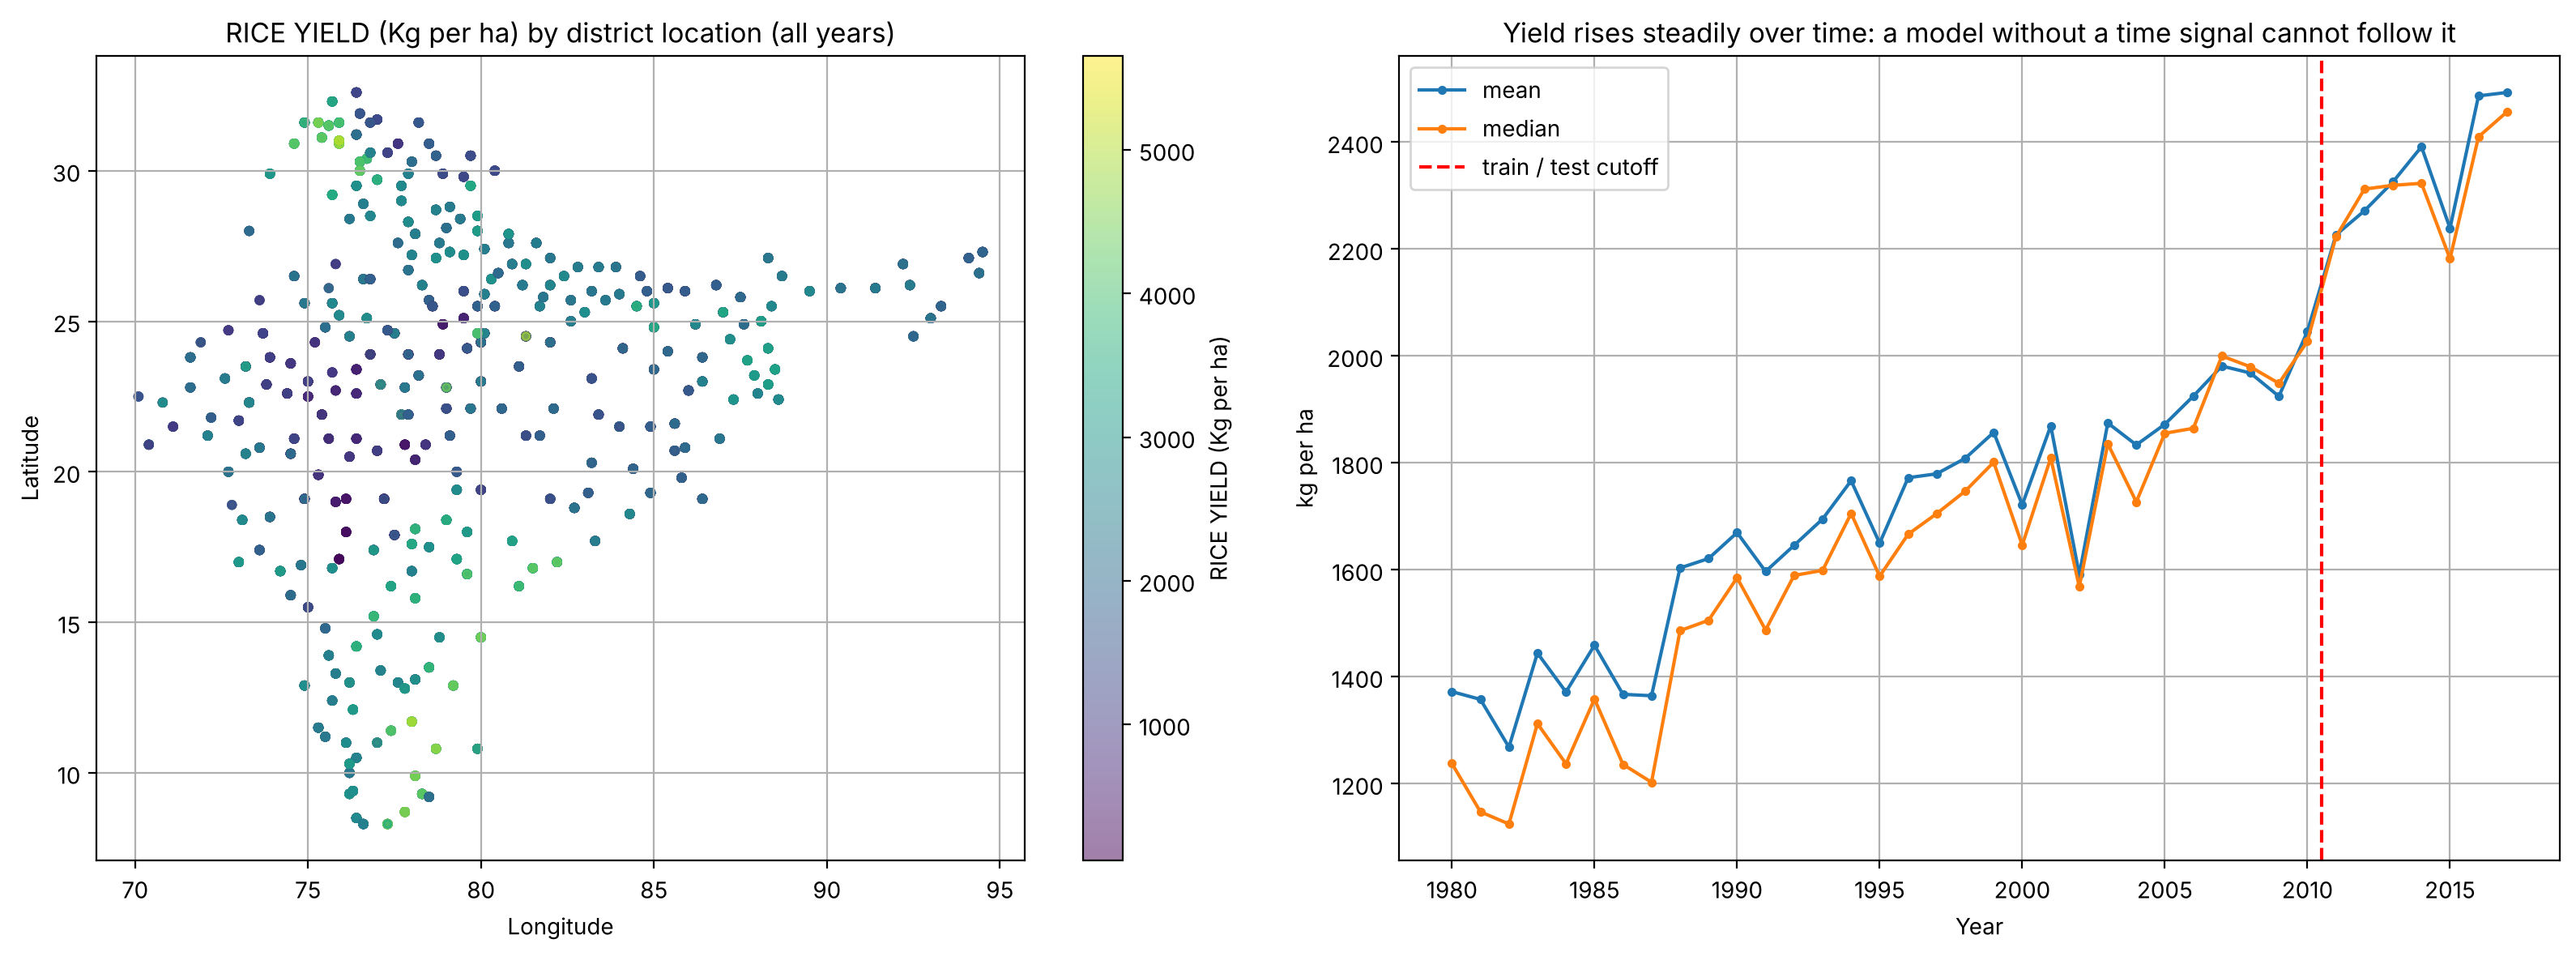

Average yield rises by about 28 kg/ha per year (1.6% of the average yield)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

model_df.plot(kind="scatter", x="Longitude", y="Latitude", c=yield_target_col, cmap="viridis",
              s=12, alpha=0.5, colorbar=True, grid=True, ax=axes[0],
              title=f"{yield_target_col} by district location (all years)")

trend_by_year = model_df.groupby("Year")[yield_target_col].agg(["mean", "median"])
trend_by_year.plot(ax=axes[1], marker="o", ms=3, grid=True,
                   title="Yield rises steadily over time: a model without a time signal cannot follow it")
axes[1].axvline(CUTOFF_YEAR + 0.5, color="red", ls="--", label="train / test cutoff")
axes[1].set_ylabel("kg per ha"); axes[1].legend()
plt.tight_layout(); plt.show()

slope = np.polyfit(trend_by_year.index, trend_by_year["mean"], 1)[0]
print(f"Average yield rises by about {slope:.0f} kg/ha per year "
      f"({slope / trend_by_year['mean'].mean():.1%} of the average yield)")

### Irrigation and monsoon

Left: districts with more irrigated rice area have higher yields. Right: this season's yield compared with the district's recent average, against how wet the monsoon was. If irrigation protects against drought, the rain-fed line should be clearly steeper than the irrigated line.

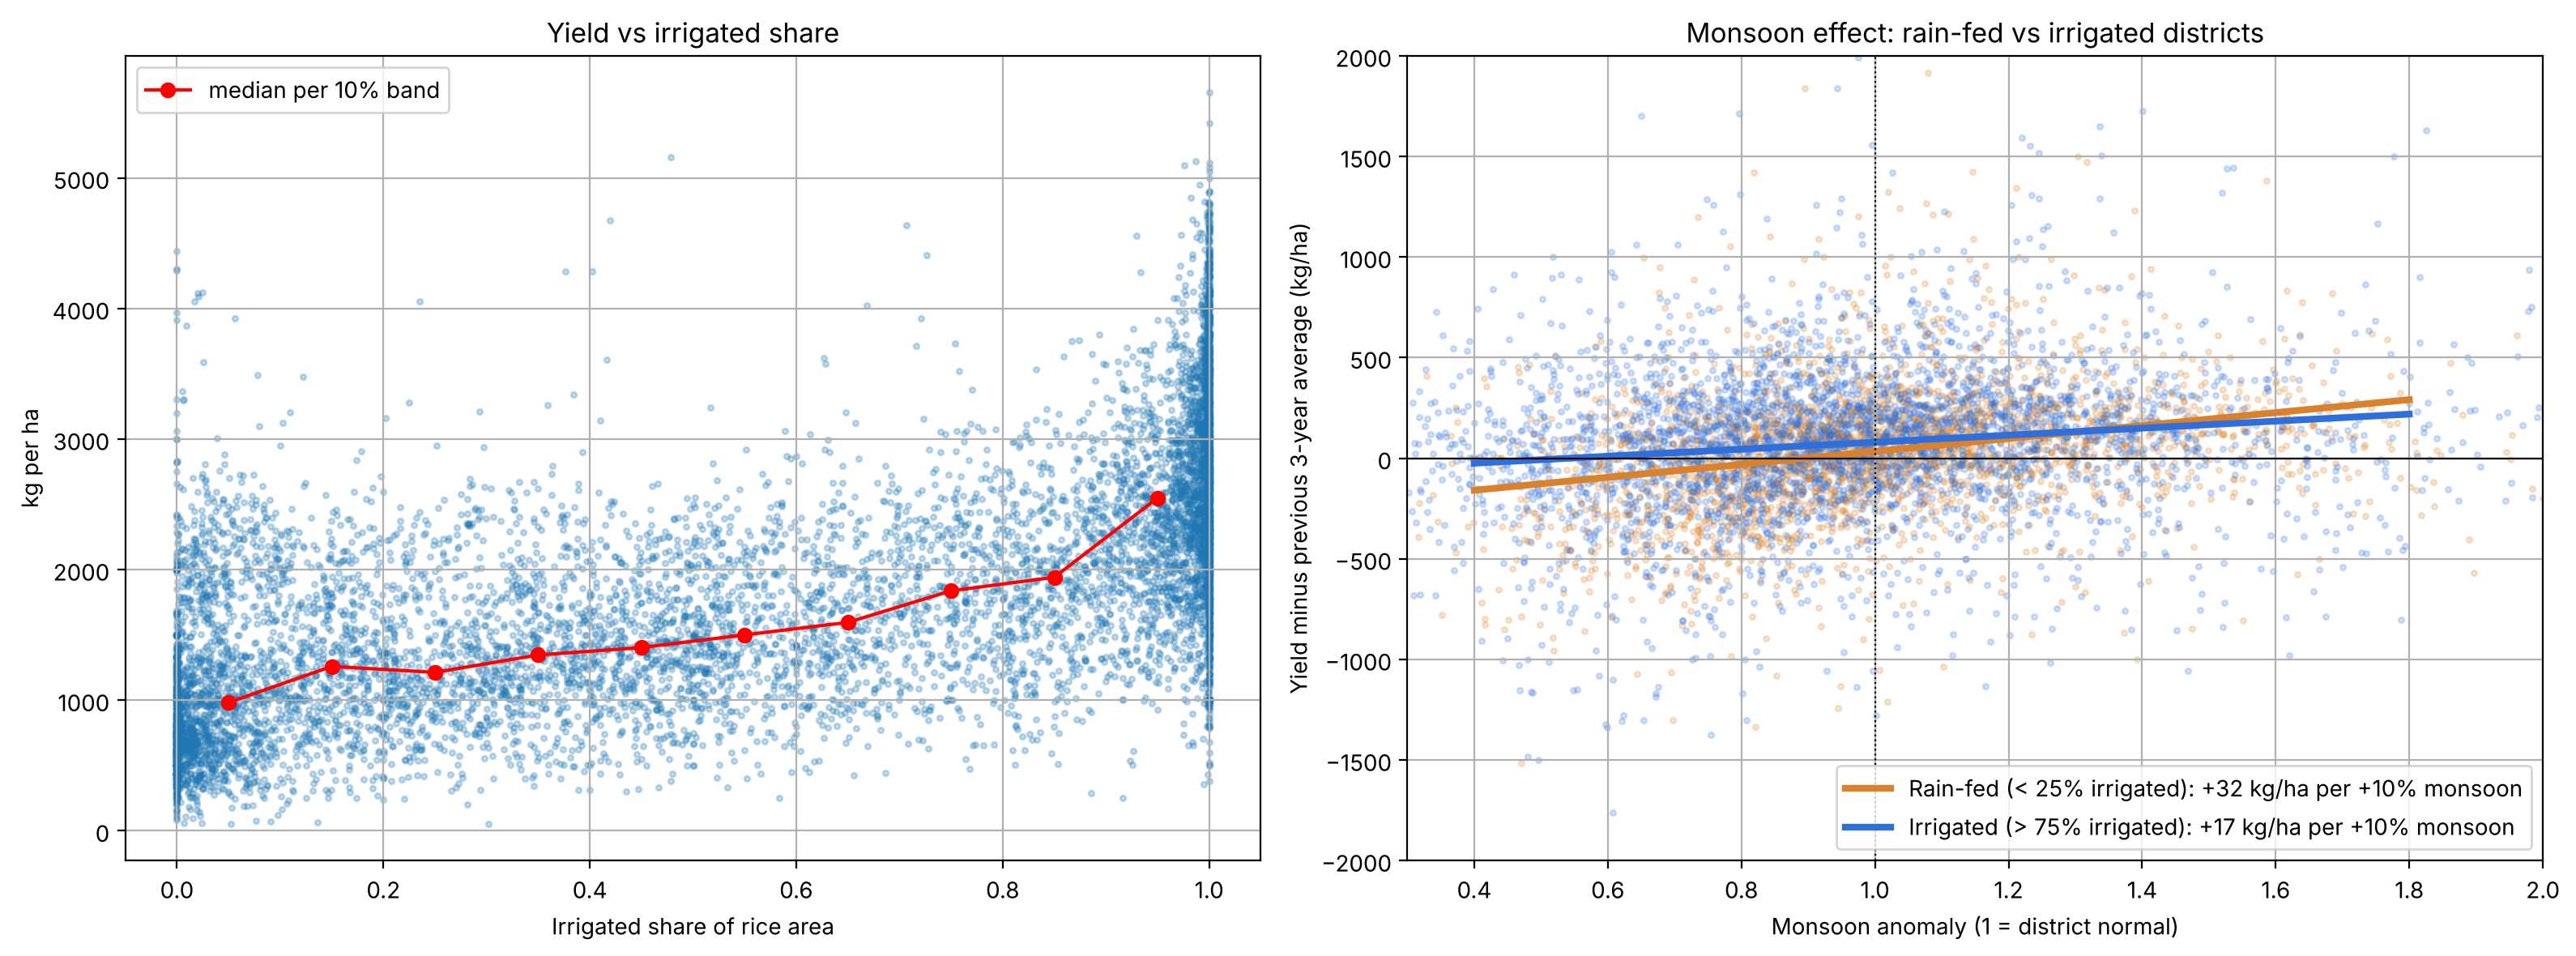

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].scatter(model_df["irrigated_share"], model_df[yield_target_col], s=6, alpha=0.25)
binned = model_df.groupby(pd.cut(model_df["irrigated_share"], np.linspace(0, 1, 11)), observed=True)
axes[0].plot([iv.mid for iv in binned.groups], binned[yield_target_col].median(), "r-o", label="median per 10% band")
axes[0].set(xlabel="Irrigated share of rice area", ylabel="kg per ha",
            title="Yield vs irrigated share"); axes[0].grid(True); axes[0].legend()

change = model_df[yield_target_col] - model_df["yield_roll3_prev"]
for label, mask, color in [("Rain-fed (< 25% irrigated)", model_df["irrigated_share"] < 0.25, "#d9822b"),
                           ("Irrigated (> 75% irrigated)", model_df["irrigated_share"] > 0.75, "#2f6fdb")]:
    x, y = model_df.loc[mask, "monsoon_anomaly"], change[mask]
    ok = x.between(0.3, 2.0) & y.notna()
    axes[1].scatter(x[ok], y[ok], s=6, alpha=0.2, color=color)
    b = np.polyfit(x[ok], y[ok], 1)
    xs = np.linspace(0.4, 1.8, 20)
    axes[1].plot(xs, np.polyval(b, xs), color=color, lw=3, label=f"{label}: {b[0] * 0.1:+.0f} kg/ha per +10% monsoon")
axes[1].axhline(0, color="black", lw=0.8); axes[1].axvline(1, color="black", lw=0.8, ls=":")
axes[1].set(xlim=(0.3, 2.0), ylim=(-2000, 2000), xlabel="Monsoon anomaly (1 = district normal)",
            ylabel="Yield minus previous 3-year average (kg/ha)",
            title="Monsoon effect: rain-fed vs irrigated districts"); axes[1].grid(True); axes[1].legend()
plt.tight_layout(); plt.show()

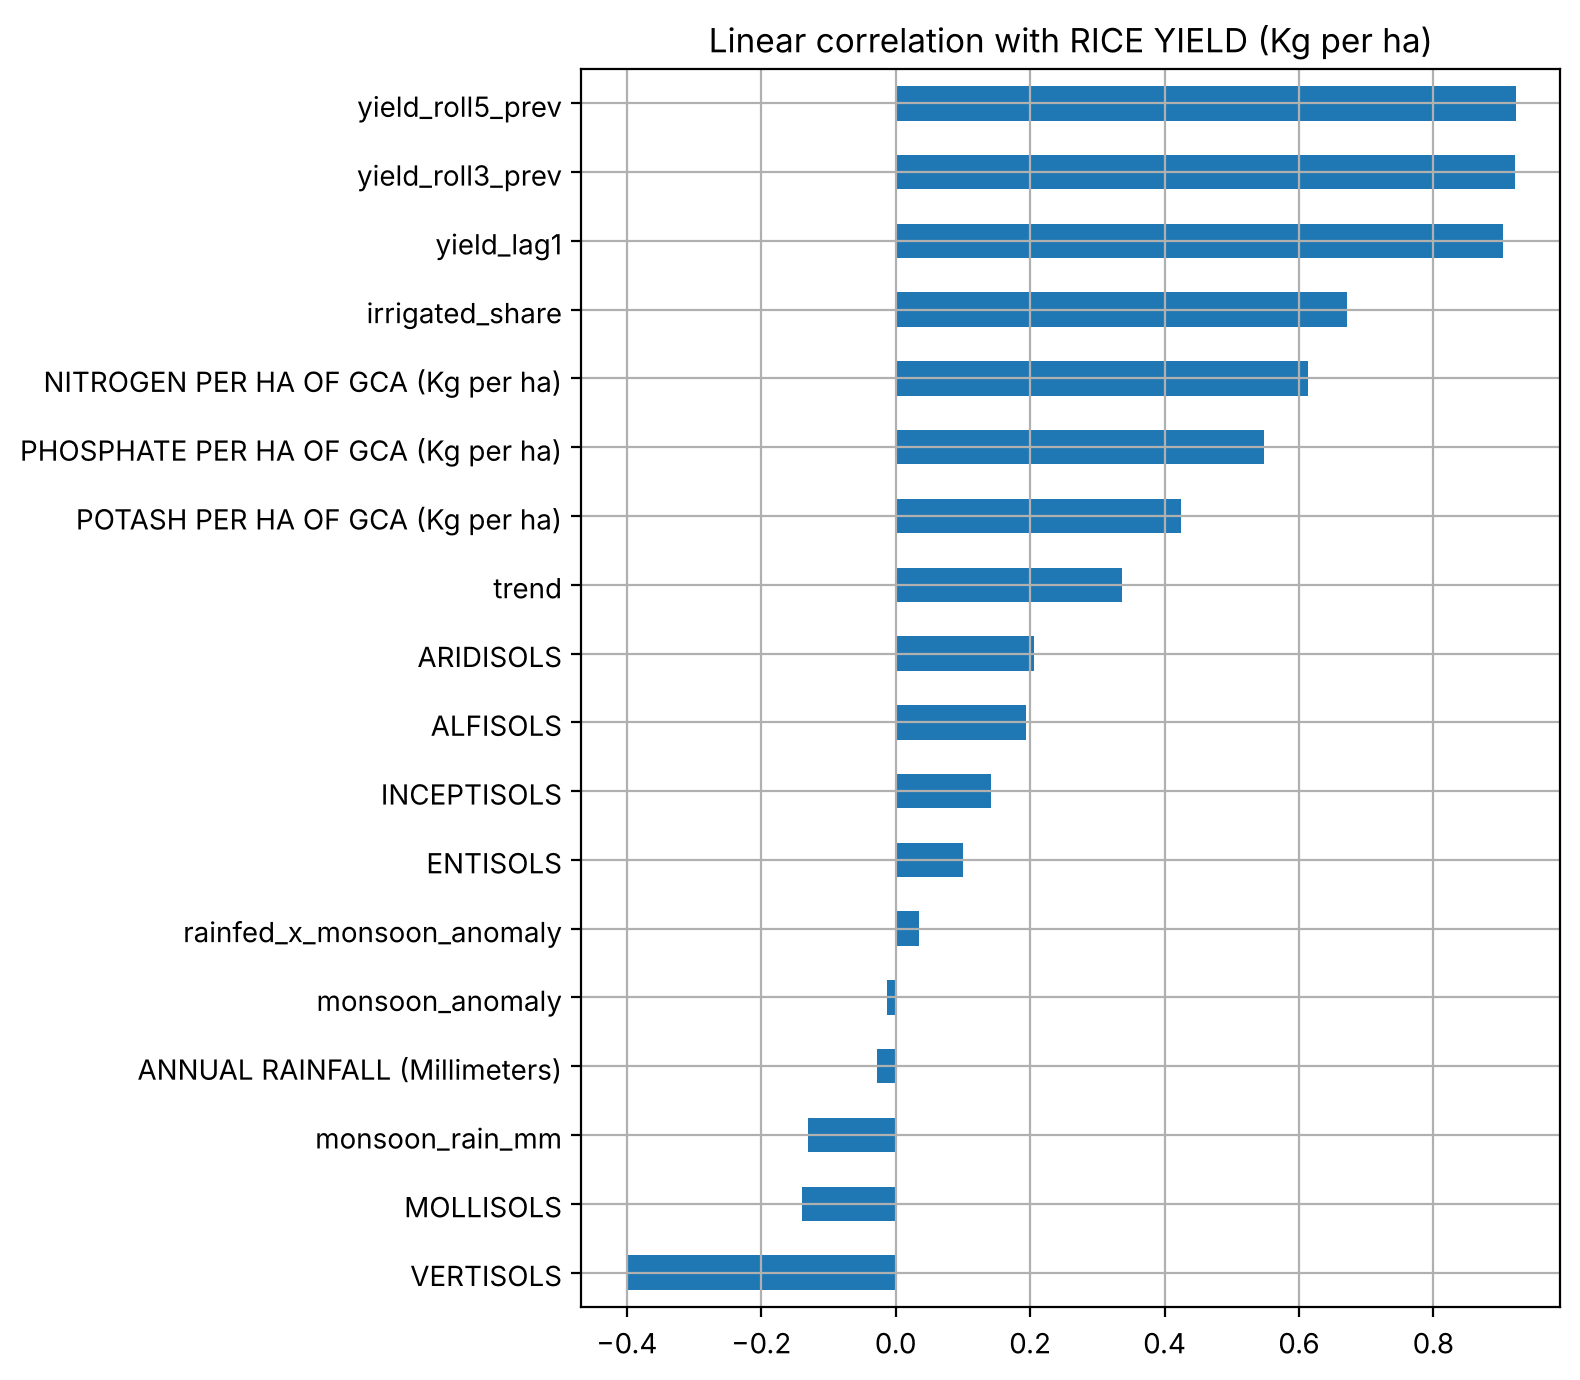

In [10]:
corr_cols = fert_cols + annual_rain_cols + water_cols + soil_cols + history_cols + ["trend", yield_target_col]
corr = model_df[corr_cols].corr()[yield_target_col].drop(yield_target_col).sort_values()

corr.plot(kind="barh", figsize=(8, 7), grid=True, title=f"Linear correlation with {yield_target_col}")
plt.tight_layout(); plt.show()

Yield history correlates most strongly with this year's yield, followed by irrigated share. History stands in for everything stable about a district (irrigation, varieties, management). The water features matter mainly for explaining **why one season differs from the district's normal**, which is what the right-hand chart above shows.

# 5. Train / test split and cross-validation folds

- **Train:** 1980–2010. **Test:** 2011–2017 (about an 80/20 split), never touched until section 11.
- **Cross-validation:** expanding-window year folds. Each fold trains on every year before a 2-year validation block. This matches how the model is used: learn from the past, predict the future. (Default `cv=5` on rows sorted by district would hold out *districts* instead of *future years*, which is the mistake iteration 1 made.)

In [11]:
iter1_cols = fert_cols + annual_rain_cols + soil_cols + geo_cols
iter2_cols = iter1_cols + history_cols + ["trend"]
iter3_cols = iter2_cols + water_cols
FEATURES = {1: iter1_cols, 2: iter2_cols, 3: iter3_cols}

train_df = model_df[model_df["Year"] <= CUTOFF_YEAR].reset_index(drop=True)
test_df  = model_df[model_df["Year"] >  CUTOFF_YEAR].reset_index(drop=True)

X_train, y_train = train_df[iter3_cols], train_df[yield_target_col]   # superset; each pipeline picks its columns
X_test,  y_test  = test_df[iter3_cols],  test_df[yield_target_col]
print(f"Train {X_train.shape}, years {train_df.Year.min()}-{train_df.Year.max()}")
print(f"Test  {X_test.shape}, years {test_df.Year.min()}-{test_df.Year.max()}")
print(f"Test mean yield = {y_test.mean():,.0f} kg/ha (train mean = {y_train.mean():,.0f})")


def year_folds(years, val_blocks=((2001, 2002), (2003, 2004), (2005, 2006), (2007, 2008), (2009, 2010))):
    # Expanding-window CV: train on years < block start, validate on the block.
    years = np.asarray(years)
    return [(np.where(years < lo)[0], np.where((years >= lo) & (years <= hi))[0]) for lo, hi in val_blocks]

cv_folds = year_folds(train_df["Year"])
for tr, va in cv_folds:
    print(f"  train {train_df.Year[tr].min()}-{train_df.Year[tr].max()} ({len(tr):,} rows) "
          f"-> validate {train_df.Year[va].min()}-{train_df.Year[va].max()} ({len(va):,} rows)")

Train (8899, 20), years 1980-2010
Test  (1947, 20), years 2011-2017
Test mean yield = 2,347 kg/ha (train mean = 1,678)
  train 1980-2000 (6,049 rows) -> validate 2001-2002 (577 rows)
  train 1980-2002 (6,626 rows) -> validate 2003-2004 (571 rows)
  train 1980-2004 (7,197 rows) -> validate 2005-2006 (572 rows)
  train 1980-2006 (7,769 rows) -> validate 2007-2008 (566 rows)
  train 1980-2008 (8,335 rows) -> validate 2009-2010 (564 rows)


# 6. Baselines (the bar every model must beat)

| Baseline | Prediction |
|---|---|
| Training mean | One number for every district and year |
| Last year | This district's yield last season |
| 3-year average | Average of this district's previous 3 seasons |
| 5-year average | Average of this district's previous 5 seasons |
| 3-year average + trend | 3-year average plus the national yearly increase learned on training data. The 3-year window is centred two seasons before the target year, so the increase is added twice |

In [12]:
results = []

def score(name, y_true, y_pred, kind):
    rmse = root_mean_squared_error(y_true, y_pred)
    results.append({"model": name, "type": kind,
                    "test RMSE": rmse,
                    "test MAE": mean_absolute_error(y_true, y_pred),
                    "RMSE % of test mean": rmse / y_true.mean() * 100,
                    "bias (actual - pred)": float(np.mean(np.asarray(y_true) - np.asarray(y_pred)))})
    return rmse

yearly_mean = train_df.groupby("Year")[yield_target_col].mean()          # training years only: no leakage
national_slope = np.polyfit(yearly_mean.index, yearly_mean.values, 1)[0]
baseline_best_guess = test_df["yield_roll3_prev"] + 2 * national_slope

score("Training mean",          y_test, np.full(len(y_test), y_train.mean()), "baseline")
score("Last year",              y_test, test_df["yield_lag1"].fillna(test_df["yield_roll3_prev"]), "baseline")
score("3-year average",         y_test, test_df["yield_roll3_prev"], "baseline")
score("5-year average",         y_test, test_df["yield_roll5_prev"], "baseline")
score("3-year average + trend", y_test, baseline_best_guess, "baseline")

pd.DataFrame(results).round(1)

,model,type,test RMSE,test MAE,RMSE % of test mean,bias (actual - pred)
0,Training mean,baseline,1150.9,916.2,49.0,669.2
1,Last year,baseline,510.0,335.5,21.7,59.9
2,3-year average,baseline,466.6,322.8,19.9,120.1
3,5-year average,baseline,475.5,336.1,20.3,172.2
4,3-year average + trend,baseline,457.2,311.2,19.5,75.4


# 7. Preprocessing pipeline

Everything (replacing -1 with missing, imputation, log transforms, scaling and feature engineering) happens inside one `ColumnTransformer`, so training and test data are processed identically and cross-validation folds never see each other's statistics. `make_preprocessing(iteration)` builds the pipeline for iteration 1, 2 or 3.

| Group | Steps | Iteration |
|---|---|---|
| fert (N, P, K) | -1 → missing, median fill, log1p, scale | 1+ |
| soil | median fill, ÷ 100 so shares are 0–1 | 1+ |
| geo | median fill, scale | 1+ |
| annual rain | -1 → missing, median fill, scale | 1+ |
| soil × fertilizer | clean, 18 products, log1p, scale | 1+ |
| N:P:K ratios | clean, 6 ratios, log1p, scale | 1+ |
| history | median fill, scale | 2+ |
| trend | scale | 2+ |
| water | median fill, scale | 3 |

In [13]:
class SoilFertInteraction(BaseEstimator, TransformerMixin):
    # Soil share x fertilizer rate: different soils respond differently to nutrients.

    def __init__(self, soil_cols, fert_cols):
        self.soil_cols = soil_cols
        self.fert_cols = fert_cols

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.soil_cols + self.fert_cols)
        return np.column_stack([X[s].values * X[f].values for s in self.soil_cols for f in self.fert_cols])

    def get_feature_names_out(self, input_features=None):
        return np.array([f"{s} x {f.split(' PER')[0]}" for s in self.soil_cols for f in self.fert_cols])


class FertRatio(BaseEstimator, TransformerMixin):
    # N:P:K balance ratios.

    def __init__(self, fert_cols):
        self.fert_cols = fert_cols

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        N, P, K = (np.asarray(X)[:, i] for i in range(3))
        eps = 1e-8
        ratios = np.column_stack([N / (P + eps), N / (K + eps), P / (K + eps),
                                  N / (P + K + eps), K / (N + P + eps), P / (K + N + eps)])
        return np.clip(np.nan_to_num(ratios, nan=0.0, posinf=0.0), 0, 1e3)

    def get_feature_names_out(self, input_features=None):
        return np.array(["N/P", "N/K", "P/K", "N/(P+K)", "K/(N+P)", "P/(K+N)"])


replace_negative = FunctionTransformer(lambda X: np.where(np.asarray(X, dtype=float) < 0, np.nan, X),
                                       feature_names_out="one-to-one")
scale_0_to_1 = FunctionTransformer(lambda X: np.asarray(X) / 100.0, feature_names_out="one-to-one")
log1p = FunctionTransformer(np.log1p, feature_names_out="one-to-one")


def clean():
    return [replace_negative, SimpleImputer(strategy="median")]


def make_preprocessing(iteration=3):
    transformers = [
        ("fert",       make_pipeline(*clean(), log1p, StandardScaler()), fert_cols),
        ("soil",       make_pipeline(SimpleImputer(strategy="median"), scale_0_to_1), soil_cols),
        ("geo",        make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), geo_cols),
        ("rain",       make_pipeline(*clean(), StandardScaler()), annual_rain_cols),
        ("soilxfert",  make_pipeline(*clean(), SoilFertInteraction(soil_cols, fert_cols), log1p, StandardScaler()),
                       soil_cols + fert_cols),
        ("fert_ratio", make_pipeline(*clean(), FertRatio(fert_cols), log1p, StandardScaler()), fert_cols),
    ]
    if iteration >= 2:
        transformers += [
            ("history", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), history_cols),
            ("trend",   StandardScaler(), ["trend"]),
        ]
    if iteration >= 3:
        # no replace_negative here: rainfed_x_monsoon_anomaly is legitimately negative in wet years
        transformers += [("water", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), water_cols)]
    return ColumnTransformer(transformers, remainder="drop")


for it in (1, 2, 3):
    print(f"Iteration {it}: {make_preprocessing(it).fit(X_train).get_feature_names_out().size} model inputs")

Iteration 1: 36 model inputs
Iteration 2: 40 model inputs
Iteration 3: 44 model inputs


# 8. Iteration 1: the original model, re-scored honestly

Same features and the same tuned HistGradientBoosting settings as the original notebook, now scored with year-based CV and on the same test rows as the baselines.

In [14]:
iter1_model = make_pipeline(
    make_preprocessing(1),
    HistGradientBoostingRegressor(max_iter=500, max_depth=4, learning_rate=0.01,
                                  min_samples_leaf=5, l2_regularization=0.0, random_state=RANDOM_STATE))

iter1_cv = -cross_val_score(iter1_model, X_train, y_train, cv=cv_folds, scoring="neg_root_mean_squared_error")
print("Year-based CV RMSE per fold:", iter1_cv.round(0), "-> mean", round(iter1_cv.mean()))

iter1_model.fit(X_train, y_train)
iter1_rmse = score("Iteration 1: original features", y_test, iter1_model.predict(X_test), "model")
print(f"Test RMSE = {iter1_rmse:,.0f} kg/ha")

Year-based CV RMSE per fold: [440. 475. 455. 506. 504.] -> mean 476


Test RMSE = 744 kg/ha


The CV score (about 476) is far below the test score. Section 4 explains why: yields in 2011–2017 are higher than anything in training, and tree models cannot predict values above those they have seen. Iteration 1 has no time signal, so it consistently predicts too low.

# 9. Model selection procedure (used by iterations 2 and 3)

For each iteration, the same procedure picks the model **using year-based CV only**:

1. Try 3 algorithms (Ridge, ExtraTrees, HistGradientBoosting) × 2 ways of framing the target:
   - **raw yield**: predict kg/ha directly
   - **change from 3-yr avg**: predict yield − previous 3-year average, then add the average back. The model only has to learn how this season differs from normal, and never has to predict yield levels unseen in training
2. Tune the best of the 6 with `RandomizedSearchCV` on the same year folds.
3. **Keep the tuned settings only if they cut CV RMSE by at least 1%.** With only 5 validation folds, smaller differences are noise, and picking the "best" of 15 random settings by a tiny margin tends to choose an over-fitted model.

> **Transparency note:** rule 3 was added after the first run of this notebook. In that run, tuning iteration 3 did not improve CV at all (334.6 → 334.6) but still switched to deeper, fully grown trees, which scored noticeably worse on the 2011–2017 test years (467 vs 453 kg/ha with default settings). The rule is reported here because it was informed by the test set; all other choices were made on CV only.

`DeltaRegressor` is a small wrapper for the second framing that still works with `cross_val_score` and `RandomizedSearchCV`.

In [15]:
class DeltaRegressor(RegressorMixin, BaseEstimator):
    # Fit `estimator` on (y - X[base_col]) and add X[base_col] back at prediction time.

    def __init__(self, estimator, base_col="yield_roll3_prev"):
        self.estimator = estimator
        self.base_col = base_col

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)
        self.estimator_.fit(X, np.asarray(y) - X[self.base_col].values)
        return self

    def predict(self, X):
        return X[self.base_col].values + self.estimator_.predict(X)


candidates = {
    "Ridge":      Ridge(alpha=1.0),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5,
                                      n_jobs=-1, random_state=RANDOM_STATE),
    "HistGB":     HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}
TARGET_MODES = ["raw yield", "change from 3-yr avg"]

param_grids = {
    "Ridge":      {"alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    "ExtraTrees": {"n_estimators": [200, 400], "max_depth": [None, 10, 20],
                   "min_samples_leaf": [1, 2, 5, 10, 20], "max_features": ["sqrt", 0.3, 0.5, 0.8]},
    "HistGB":     {"max_iter": [200, 300, 500, 800], "learning_rate": [0.01, 0.03, 0.05, 0.1],
                   "max_depth": [2, 3, 4, 6, None], "min_samples_leaf": [10, 20, 50, 100],
                   "l2_regularization": [0.0, 0.1, 1.0, 10.0]},
}


def build(name, target_mode, iteration, estimator=None):
    est = clone(estimator if estimator is not None else candidates[name])
    pipe = Pipeline([("prep", make_preprocessing(iteration)), ("model", est)])
    return pipe if target_mode == "raw yield" else DeltaRegressor(pipe)


MIN_TUNING_GAIN = 0.01   # keep tuned settings only if they cut CV RMSE by at least 1%


def select_and_tune(iteration, n_iter=15):
    rows = []
    for name in candidates:
        for mode in TARGET_MODES:
            fold_rmse = -cross_val_score(build(name, mode, iteration), X_train, y_train, cv=cv_folds,
                                         scoring="neg_root_mean_squared_error", n_jobs=-1)
            rows.append({"model": name, "target": mode,
                         "CV RMSE mean": fold_rmse.mean(), "CV RMSE std": fold_rmse.std()})
    table = pd.DataFrame(rows).sort_values("CV RMSE mean").reset_index(drop=True).round(1)

    best_name, best_mode = table.loc[0, ["model", "target"]]
    prefix = "model__" if best_mode == "raw yield" else "estimator__model__"
    search = RandomizedSearchCV(build(best_name, best_mode, iteration),
                                {prefix + k: v for k, v in param_grids[best_name].items()},
                                n_iter=n_iter, cv=cv_folds, scoring="neg_root_mean_squared_error",
                                random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train, y_train)

    default_cv, tuned_cv = table.loc[0, "CV RMSE mean"], -search.best_score_
    print(f"Iteration {iteration} CV winner: {best_name} ({best_mode}); "
          f"CV RMSE {default_cv:,.1f} default -> {tuned_cv:,.1f} best tuned")
    if tuned_cv < default_cv * (1 - MIN_TUNING_GAIN):
        print("Tuned settings kept:", {k.split("__")[-1]: v for k, v in search.best_params_.items()})
        model, model_cv = search.best_estimator_, tuned_cv
    else:
        print(f"Tuning gain below {MIN_TUNING_GAIN:.0%}: default settings kept (gain is within noise)")
        model, model_cv = build(best_name, best_mode, iteration).fit(X_train, y_train), default_cv
    return table, model, model_cv, best_name, best_mode

# 10. Iterations 2 and 3

## 10.1 Iteration 2: history + trend

In [16]:
cv_table_2, model_2, cv_2, name_2, mode_2 = select_and_tune(2)
cv_table_2

Iteration 2 CV winner: ExtraTrees (raw yield); CV RMSE 344.3 default -> 343.8 best tuned
Tuning gain below 1%: default settings kept (gain is within noise)


,model,target,CV RMSE mean,CV RMSE std
0,ExtraTrees,raw yield,344.3,20.5
1,Ridge,raw yield,351.2,27.0
2,Ridge,change from 3-yr avg,351.2,27.0
3,HistGB,raw yield,368.1,43.1
4,ExtraTrees,change from 3-yr avg,378.4,45.6
5,HistGB,change from 3-yr avg,380.2,47.1


## 10.2 Iteration 3: + irrigation and monsoon

In [17]:
cv_table_3, model_3, cv_3, name_3, mode_3 = select_and_tune(3)
cv_table_3

Iteration 3 CV winner: ExtraTrees (raw yield); CV RMSE 334.6 default -> 334.6 best tuned
Tuning gain below 1%: default settings kept (gain is within noise)


,model,target,CV RMSE mean,CV RMSE std
0,ExtraTrees,raw yield,334.6,20.4
1,Ridge,raw yield,345.9,24.9
2,Ridge,change from 3-yr avg,345.9,24.9
3,HistGB,raw yield,356.5,40.7
4,ExtraTrees,change from 3-yr avg,360.9,36.6
5,HistGB,change from 3-yr avg,366.1,40.5


# 11. Final evaluation on 2011–2017

Each iteration's selected model is scored on the test set once. The test set played no part in any choice above.

In [18]:
pred_2 = model_2.predict(X_test)
pred_3 = model_3.predict(X_test)
label_2 = f"Iteration 2: history + trend ({name_2}, {mode_2})"
label_3 = f"Iteration 3: + irrigation & monsoon ({name_3}, {mode_3})"
score(label_2, y_test, pred_2, "model")
score(label_3, y_test, pred_3, "model")

results_df = (pd.DataFrame(results).drop_duplicates("model", keep="last")
              .sort_values("test RMSE").reset_index(drop=True).round(1))
results_df

,model,type,test RMSE,test MAE,RMSE % of test mean,bias (actual - pred)
0,Iteration 3: + irrigation & monsoon (ExtraTree...,model,452.7,319.4,19.3,137.1
1,"Iteration 2: history + trend (ExtraTrees, raw ...",model,455.0,320.9,19.4,128.9
2,3-year average + trend,baseline,457.2,311.2,19.5,75.4
3,3-year average,baseline,466.6,322.8,19.9,120.1
4,5-year average,baseline,475.5,336.1,20.3,172.2
5,Last year,baseline,510.0,335.5,21.7,59.9
6,Iteration 1: original features,model,744.4,570.8,31.7,408.0
7,Training mean,baseline,1150.9,916.2,49.0,669.2


Test-period mean yield: 2,347 kg/ha

Iteration 1 : 744 kg/ha (32% of mean)
Iteration 2 : 455 kg/ha (19% of mean)  38.9% better than iteration 1
Iteration 3 : 453 kg/ha (19% of mean)  0.5% better than iteration 2
Best naive baseline (3-year average + trend): 457 kg/ha
Iteration 3 vs best baseline: 1.0% better


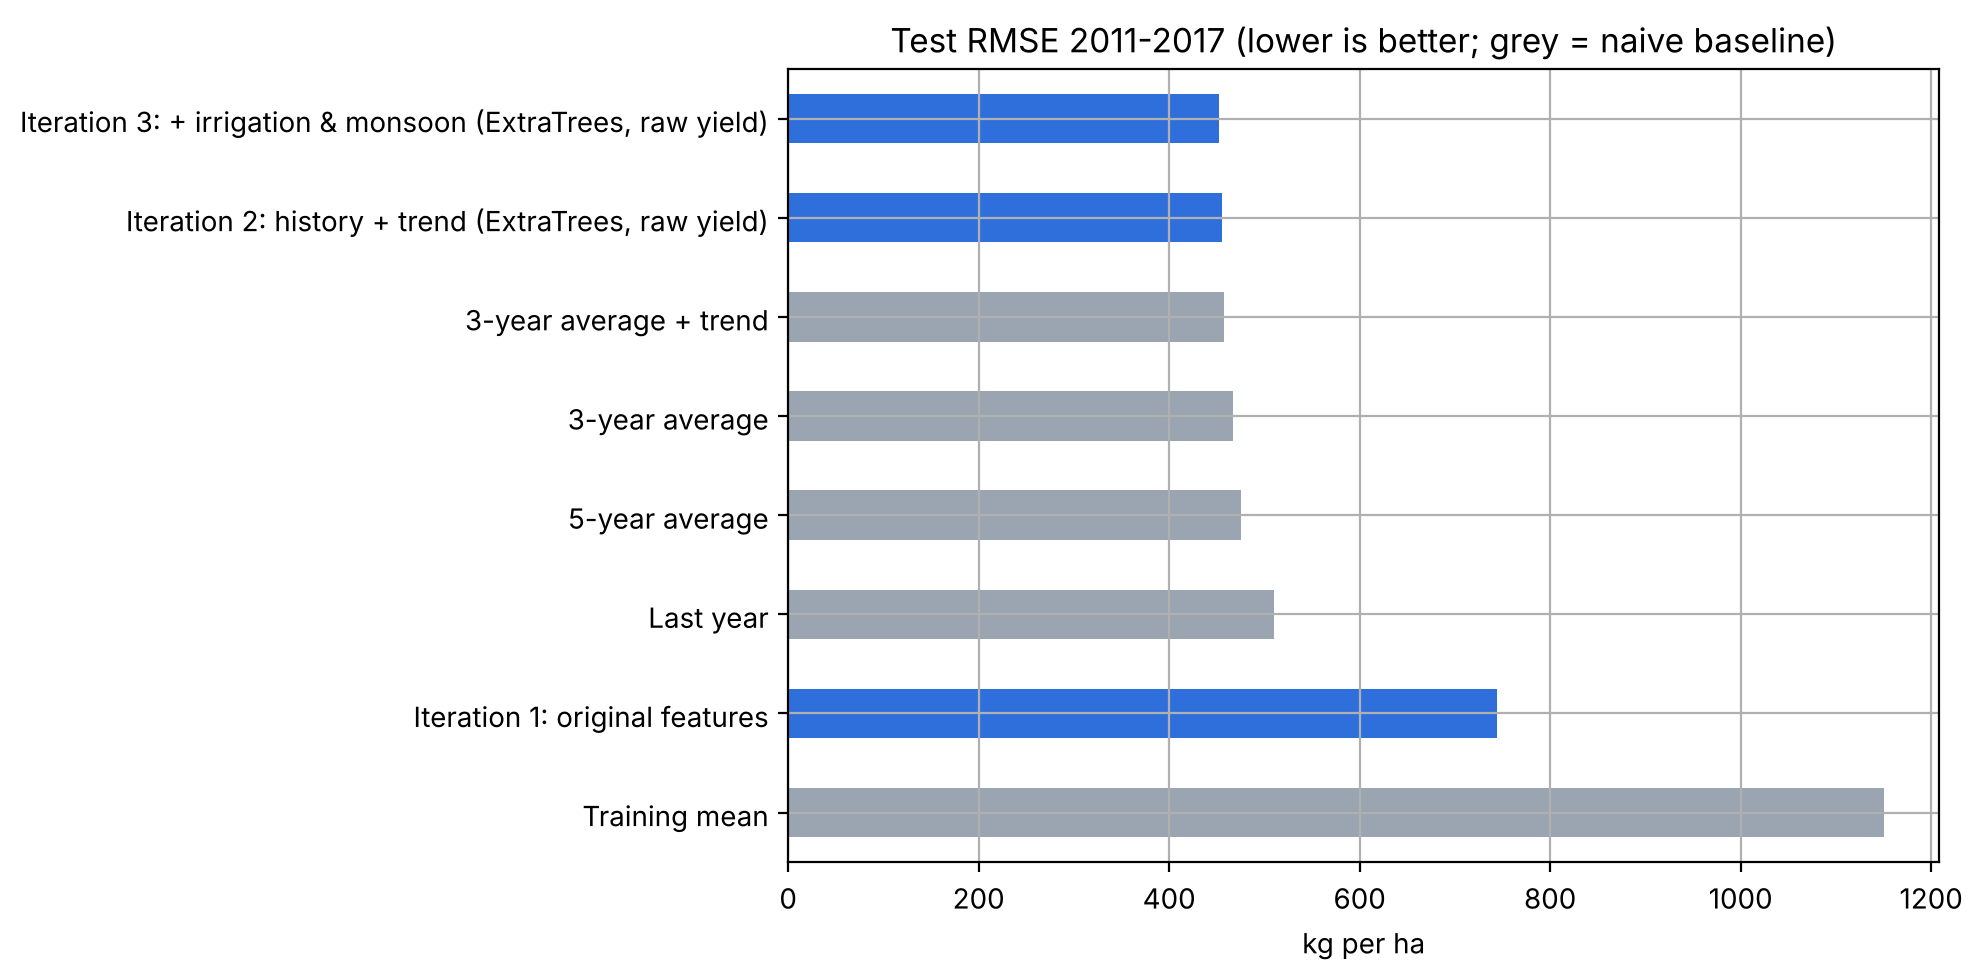

In [19]:
def rmse_of(label):
    return results_df.loc[results_df.model == label, "test RMSE"].iloc[0]

best_baseline = results_df[results_df.type == "baseline"].iloc[0]
r1, r2, r3 = rmse_of("Iteration 1: original features"), rmse_of(label_2), rmse_of(label_3)

print(f"Test-period mean yield: {y_test.mean():,.0f} kg/ha\n")
print(f"Iteration 1 : {r1:,.0f} kg/ha ({r1 / y_test.mean():.0%} of mean)")
print(f"Iteration 2 : {r2:,.0f} kg/ha ({r2 / y_test.mean():.0%} of mean)  {1 - r2 / r1:.1%} better than iteration 1")
print(f"Iteration 3 : {r3:,.0f} kg/ha ({r3 / y_test.mean():.0%} of mean)  {1 - r3 / r2:.1%} better than iteration 2")
print(f"Best naive baseline ({best_baseline['model']}): {best_baseline['test RMSE']:,.0f} kg/ha")
print(f"Iteration 3 vs best baseline: {1 - r3 / best_baseline['test RMSE']:.1%} better")

colors = results_df["type"].map({"baseline": "#9aa5b1", "model": "#2f6fdb"})
ax = results_df.plot(kind="barh", x="model", y="test RMSE", color=colors, legend=False,
                     figsize=(10, 5), grid=True, title="Test RMSE 2011-2017 (lower is better; grey = naive baseline)")
ax.invert_yaxis(); ax.set_xlabel("kg per ha"); ax.set_ylabel(""); plt.tight_layout(); plt.show()

# 12. What does each data source add? (feature-group test)

Permutation importance is misleading here: last year's yield and the 3- and 5-year averages carry almost the same information, so shuffling one leaves the others, and each looks unimportant. Instead, the iteration-3 model type (with its selected settings) is refit on **growing sets of feature groups**, and year-based CV and test RMSE are compared. This answers the practical question: **is each data source worth collecting?**

In [20]:
groups = {
    "history + trend":           history_cols + ["trend"],
    "+ annual rainfall":         annual_rain_cols,
    "+ monsoon rain & anomaly":  ["monsoon_rain_mm", "monsoon_anomaly"],
    "+ irrigated share":         ["irrigated_share"],
    "+ rain-fed x monsoon":      ["rainfed_x_monsoon_anomaly"],
    "+ fertilizer":              fert_cols,
    "+ soil":                    soil_cols,
    "+ location":                geo_cols,
}

final_est = clone(model_3 if mode_3 == "raw yield" else model_3.estimator)["model"]


def subset_model(cols):
    # Same model type, settings and target framing, restricted to `cols` (no soil x fertilizer / ratio features).
    prep = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), cols)])
    pipe = Pipeline([("prep", prep), ("model", clone(final_est))])
    return pipe if mode_3 == "raw yield" else DeltaRegressor(pipe)


ablation, cols = [], []
subset_preds = {}
for label, group in groups.items():
    cols = cols + group
    m = subset_model(cols)
    cv = -cross_val_score(m, X_train[cols], y_train, cv=cv_folds,
                          scoring="neg_root_mean_squared_error", n_jobs=-1).mean()
    subset_preds[label] = m.fit(X_train[cols], y_train).predict(X_test[cols])
    ablation.append({"features": label, "n columns": len(cols), "CV RMSE": cv,
                     "test RMSE": root_mean_squared_error(y_test, subset_preds[label])})

ablation.append({"features": "all 44 inputs (iteration 3 model)",
                 "n columns": make_preprocessing(3).fit(X_train).get_feature_names_out().size,
                 "CV RMSE": cv_3, "test RMSE": r3})

ablation_df = pd.DataFrame(ablation)
ablation_df["CV change"] = ablation_df["CV RMSE"].diff()
ablation_df["test change"] = ablation_df["test RMSE"].diff()
ablation_df.round(1)

,features,n columns,CV RMSE,test RMSE,CV change,test change
0,history + trend,4,352.5,445.6,NaN,NaN
1,+ annual rainfall,5,349.8,446.7,-2.7,1.1
2,+ monsoon rain & anomaly,7,344.5,441.5,-5.3,-5.1
3,+ irrigated share,8,339.8,443.2,-4.7,1.6
4,+ rain-fed x monsoon,9,338.5,442.5,-1.4,-0.6
5,+ fertilizer,12,337.6,443.5,-0.9,1.0
6,+ soil,18,335.5,446.7,-2.0,3.2
7,+ location,20,334.5,448.7,-1.0,2.0
8,all 44 inputs (iteration 3 model),44,334.6,452.7,0.1,4.0


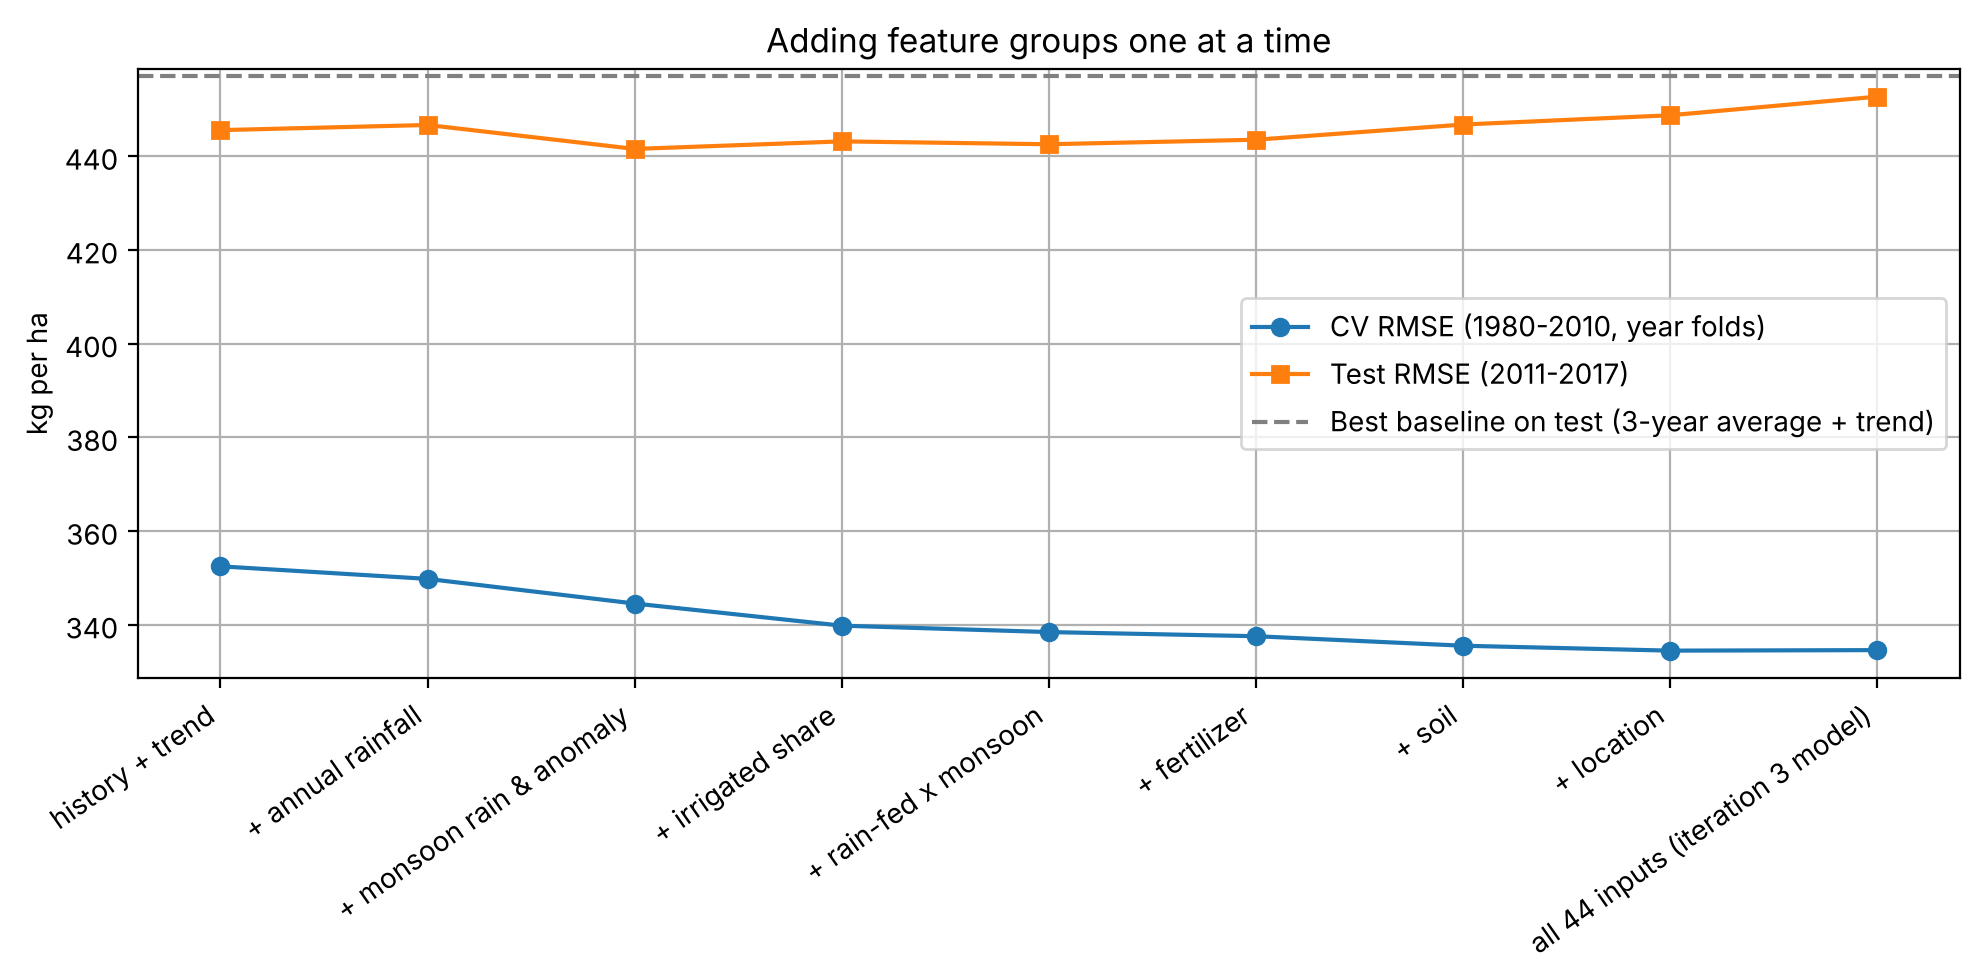

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ablation_df["features"], ablation_df["CV RMSE"], "o-", label="CV RMSE (1980-2010, year folds)")
ax.plot(ablation_df["features"], ablation_df["test RMSE"], "s-", label="Test RMSE (2011-2017)")
ax.axhline(best_baseline["test RMSE"], color="grey", ls="--", label=f"Best baseline on test ({best_baseline['model']})")
ax.set_ylabel("kg per ha"); ax.set_title("Adding feature groups one at a time"); ax.grid(True); ax.legend()
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

## 12.1 Recommended model: the simplest feature set within noise of the best

The same 1% rule used for tuning is applied to features: among the feature sets whose CV RMSE is within 1% of the best, pick the one with the **fewest columns**. Fewer inputs means less data to collect each season, fewer things that can break, and less room to overfit. This choice uses CV only; the test score is printed afterwards for information.

In [22]:
best_cv = ablation_df["CV RMSE"].min()
eligible = ablation_df[ablation_df["CV RMSE"] <= best_cv * (1 + MIN_TUNING_GAIN)]
recommended = eligible.sort_values("n columns").iloc[0]

print(f"Best CV RMSE: {best_cv:,.1f}; eligible (within {MIN_TUNING_GAIN:.0%}): {len(eligible)} feature sets")
print(f"Recommended: '{recommended['features']}' with {recommended['n columns']} columns, "
      f"CV RMSE {recommended['CV RMSE']:,.1f}")
print(f"Test RMSE {recommended['test RMSE']:,.1f} kg/ha -> "
      f"{1 - recommended['test RMSE'] / best_baseline['test RMSE']:.1%} better than the best baseline, "
      f"{1 - recommended['test RMSE'] / r2:.1%} better than iteration 2")

recommended_cols = []
for label, group in groups.items():
    recommended_cols += group
    if label == recommended["features"]:
        break
print("\nColumns:", recommended_cols)

Best CV RMSE: 334.5; eligible (within 1%): 4 feature sets
Recommended: '+ fertilizer' with 12 columns, CV RMSE 337.6
Test RMSE 443.5 kg/ha -> 3.0% better than the best baseline, 2.5% better than iteration 2

Columns: ['yield_lag1', 'yield_roll3_prev', 'yield_roll5_prev', 'trend', 'ANNUAL RAINFALL (Millimeters)', 'monsoon_rain_mm', 'monsoon_anomaly', 'irrigated_share', 'rainfed_x_monsoon_anomaly', 'NITROGEN PER HA OF GCA (Kg per ha)', 'PHOSPHATE PER HA OF GCA (Kg per ha)', 'POTASH PER HA OF GCA (Kg per ha)']


# 13. Error analysis

Where does the final model still go wrong, and where did irrigation and monsoon data help most?

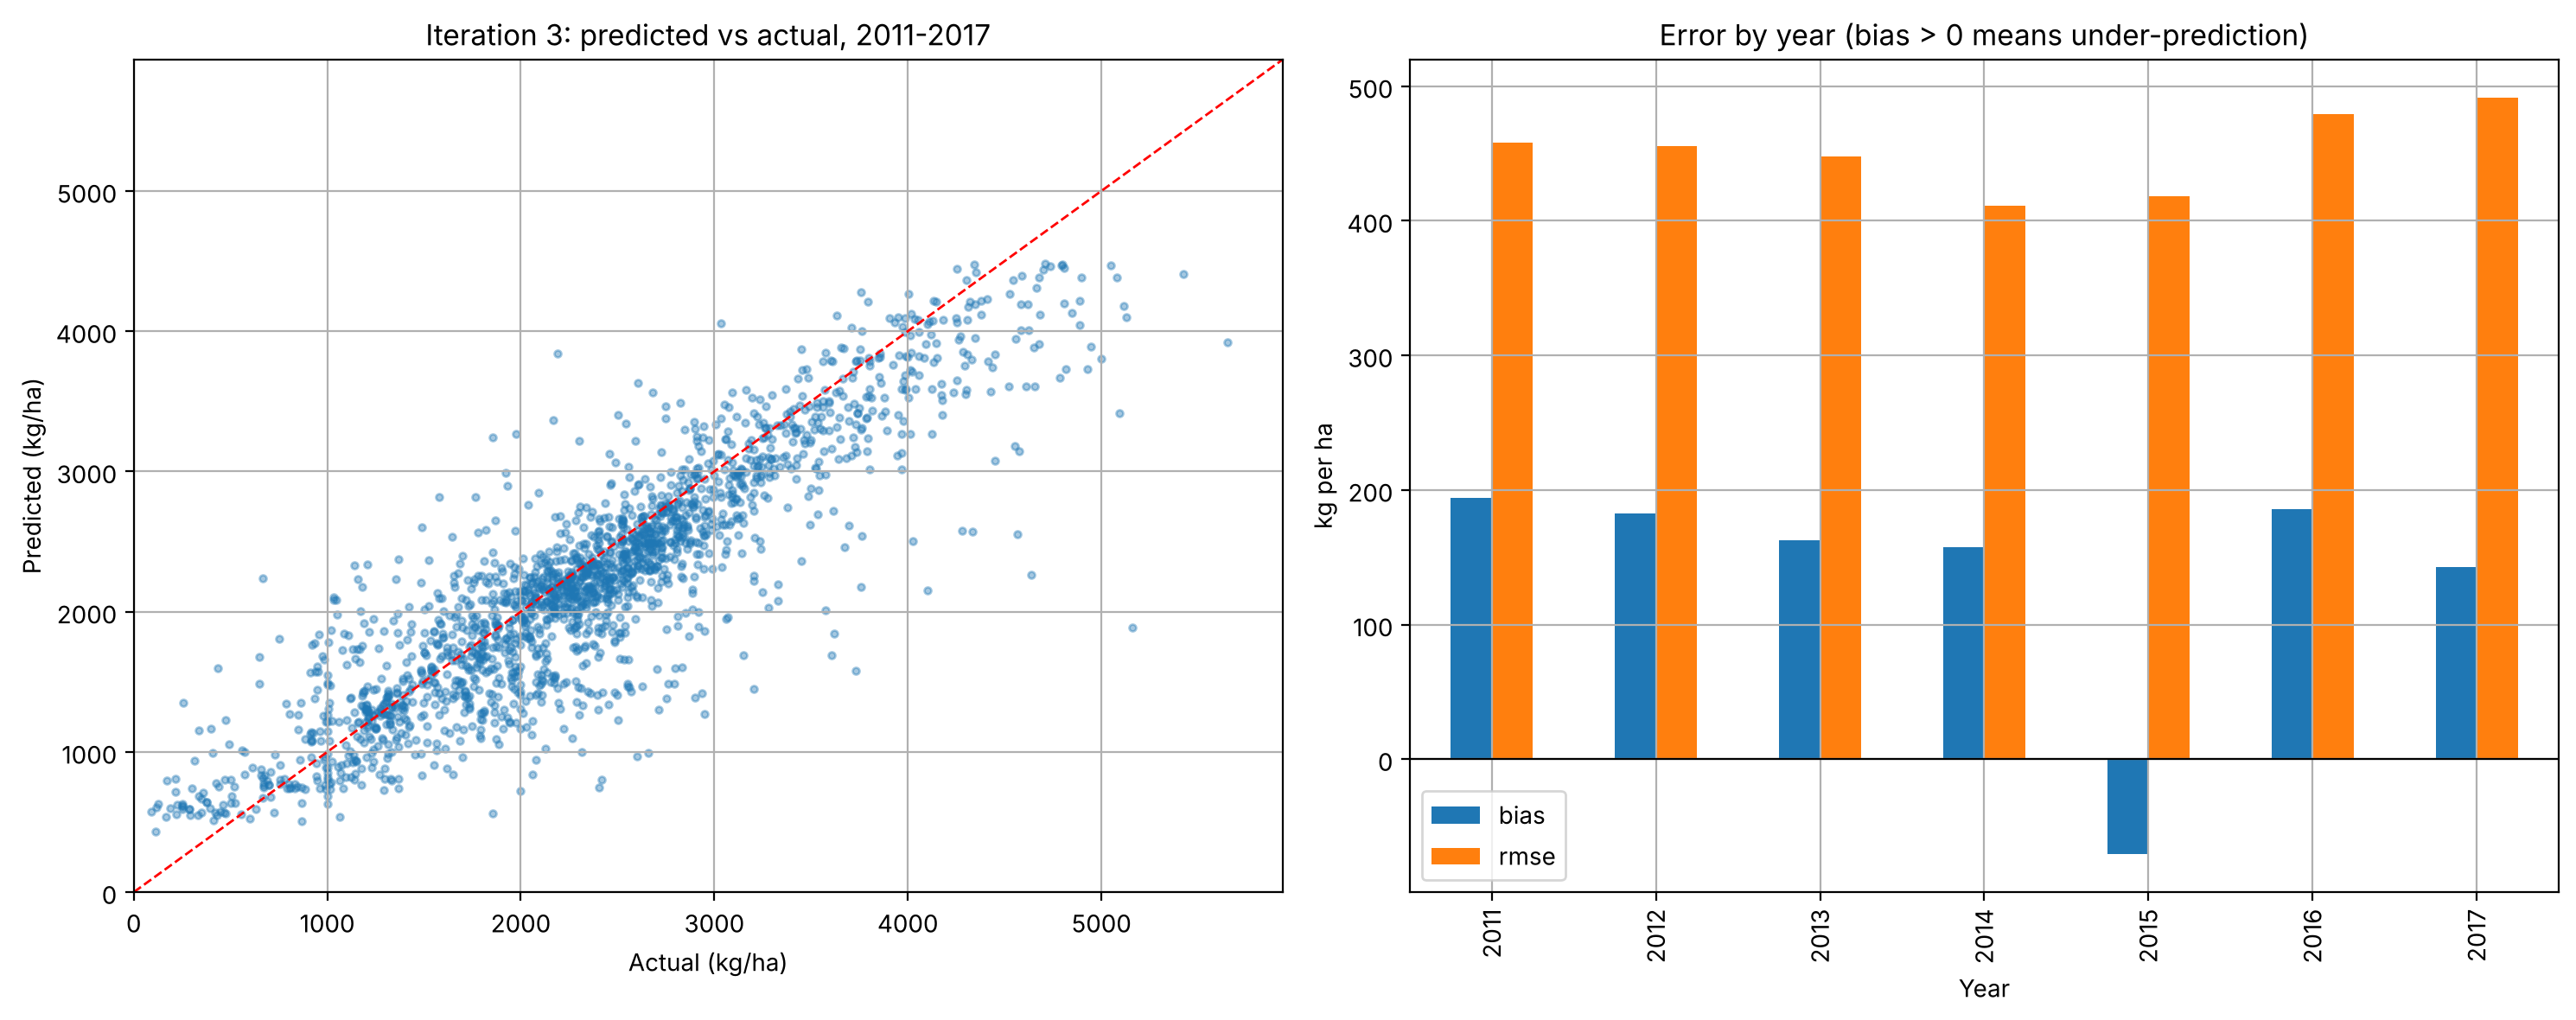

,bias,rmse
Year,,
2011,194.0,458.0
2012,183.0,456.0
2013,163.0,448.0
2014,157.0,411.0
2015,-71.0,419.0
2016,186.0,479.0
2017,143.0,492.0


In [23]:
test_eval = test_df[["Year", "State Name", "Dist Name", "irrigated_share", yield_target_col]].copy()
test_eval["pred"] = pred_3
test_eval["residual"] = test_eval[yield_target_col] - test_eval["pred"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

lim = [0, test_eval[[yield_target_col, "pred"]].max().max() * 1.05]
axes[0].scatter(test_eval[yield_target_col], test_eval["pred"], s=8, alpha=0.4)
axes[0].plot(lim, lim, "r--", lw=1)
axes[0].set(xlim=lim, ylim=lim, xlabel="Actual (kg/ha)", ylabel="Predicted (kg/ha)",
            title="Iteration 3: predicted vs actual, 2011-2017"); axes[0].grid(True)

by_year = test_eval.groupby("Year").agg(bias=("residual", "mean"),
                                        rmse=("residual", lambda r: np.sqrt((r ** 2).mean())))
by_year.plot(kind="bar", ax=axes[1], grid=True, title="Error by year (bias > 0 means under-prediction)")
axes[1].axhline(0, color="black", lw=0.8); axes[1].set_ylabel("kg per ha")
plt.tight_layout(); plt.show()
by_year.round(0)

### Error by irrigation level: where did iteration 3 help?

In [24]:
bands = pd.cut(test_eval["irrigated_share"], [0, 0.25, 0.75, 1.0], include_lowest=True,
               labels=["Rain-fed (< 25%)", "Mixed (25-75%)", "Irrigated (> 75%)"])
rmse = lambda y, p: np.sqrt(np.mean((y - p) ** 2))

by_irrigation = pd.DataFrame({
    "rows":                    test_eval.groupby(bands, observed=True).size(),
    "mean yield":              test_eval.groupby(bands, observed=True)[yield_target_col].mean(),
    "baseline RMSE":           [rmse(y_test[m], baseline_best_guess[m]) for m in [bands == b for b in bands.cat.categories]],
    "iteration 2 RMSE":        [rmse(y_test[m], pred_2[m]) for m in [bands == b for b in bands.cat.categories]],
    "iteration 3 RMSE":        [rmse(y_test[m], pred_3[m]) for m in [bands == b for b in bands.cat.categories]],
})
by_irrigation["iteration 3 vs 2"] = (by_irrigation["iteration 3 RMSE"] / by_irrigation["iteration 2 RMSE"] - 1) * 100
by_irrigation.round(1)

,rows,mean yield,baseline RMSE,iteration 2 RMSE,iteration 3 RMSE,iteration 3 vs 2
irrigated_share,,,,,,
Rain-fed (< 25%),361,1660.9,463.0,458.7,469.6,2.4
Mixed (25-75%),379,1983.0,569.8,548.0,541.9,-1.1
Irrigated (> 75%),870,2860.3,433.8,439.3,430.2,-2.1


In [25]:
by_state = (test_eval.groupby("State Name")
            .agg(districts=("Dist Name", "nunique"),
                 irrigated=("irrigated_share", "mean"),
                 mean_yield=(yield_target_col, "mean"),
                 bias=("residual", "mean"),
                 rmse=("residual", lambda r: np.sqrt((r ** 2).mean())))
            .assign(rmse_pct=lambda d: d.rmse / d.mean_yield * 100)
            .sort_values("rmse_pct", ascending=False).round(2))
by_state

,districts,irrigated,mean_yield,bias,rmse,rmse_pct
State Name,,,,,,
Madhya Pradesh,34,0.33,1671.45,279.03,690.93,41.34
Orissa,13,0.51,1930.71,120.28,687.35,35.60
Jharkhand,6,0.07,1897.22,285.44,628.02,33.10
Maharashtra,21,NaN,1485.76,33.33,411.27,27.68
Bihar,11,0.63,2355.63,345.57,640.76,27.20
Chhattisgarh,6,0.29,1710.45,95.11,423.04,24.73
Tamil Nadu,12,0.84,4005.73,414.26,845.55,21.11
Rajasthan,15,0.58,1946.29,91.11,398.11,20.45
Gujarat,11,0.62,2060.15,164.79,348.89,16.94


# 14. Conclusions

The numbers below come from this run (fixed random seeds); rerunning with another crop will change them.

## What each iteration achieved (test RMSE, 2011–2017, kg/ha)

| | Test RMSE | % of test mean | vs best baseline (457) |
|---|---|---|---|
| Iteration 1: original features | 744 | 32% | 63% worse |
| Iteration 2: + history + trend | 455 | 19% | 0.5% better |
| Iteration 3: + irrigation + monsoon (all 44 inputs) | 453 | 19% | 1.0% better |
| **Recommended: 12-column model** (history, trend, annual + monsoon rain, irrigation, rain-fed × monsoon, fertilizer) | **444** | **19%** | **3.0% better** |

## Findings

1. **Baselines changed the story.** Iteration 1 lost to "same yield as last year" (510). Any yield model has to be judged against naive forecasts, not against zero.
2. **Time was iteration 1's main problem.** Rice yields rose about 28 kg/ha per year. Without history or a trend, tree models cannot predict above the yields seen in training. Fixing this cut error by about 39%.
3. **Monsoon rainfall is the most useful new data.** In the feature-group test it is the only group that clearly improved **both** CV (−5.3) and test (−5.1). The June–September anomaly matters more than annual totals.
4. **Irrigation behaves as expected, but most of its value is already in yield history.** Irrigated districts yield far more (left chart, section 4), and a 10% wetter monsoon lifts rain-fed yields about twice as much as irrigated ones (+32 vs +17 kg/ha). But irrigation changes slowly, so a district's recent yields already reflect it. Adding it improved CV (−4.7) but not test.
5. **Fertilizer, soil and location add little once history is known.** Fertilizer stays in the recommended model only because it is within the 1% CV rule; it barely moves either score. Soil and location keep improving CV slightly while test gets worse: the model is learning to tell districts apart (which history already does) rather than explaining why a season differs.
6. **The biggest remaining error is the trend, not missing features.** Every model, and every baseline, under-predicts the test years (iteration 3: +137 kg/ha on average; positive in 6 of 7 years). Yields in 2011–2017 rose faster than the 1980–2010 trend. 2015 is the exception: a weak-monsoon year where the model over-predicted.
7. **Small tuning gains are noise.** Tuning that did not improve CV still picked an over-fitted model in the first run (see the note in section 9), which is why the 1% rule exists.

**What this means for the policy question:** to rank districts for next season, a 3-year average plus trend is a strong, transparent default. The ML model adds about 3% on top, almost all of it from monsoon rainfall. The largest gains would come from data that explains *this season*: monsoon timing within the season and the sowing-season irrigated area.

## Limitations

- **Not causal.** The model cannot say what happens if a district changes its fertilizer use or irrigation.
- **Water data gaps.** About 10% of rows have no irrigation figure (Maharashtra and West Bengal have none in the test years), and about 13% have no complete monsoon record; these are filled with the median.
- **One season ahead only.** Forecasting several years ahead would need a different setup.
- **Test period of 7 years** with a faster-than-usual rise in yields; results could differ in another period.

## Next iterations

1. **Handle the trend directly:** model the change from a state-level trend line instead of the raw yield, so faster-rising states are not under-predicted.
2. **Finer monsoon timing:** June rainfall (sowing) and August–September rainfall (grain filling) separately, plus dry spells, instead of one 4-month total.
3. **Temperature and heat stress** during grain filling ([Climatology Lab TerraClimate](https://www.climatologylab.org/)).
4. **Thailand adaptation:** rebuild the same pipeline with Land Development Department soil data ([iddindee.ldd.go.th](https://iddindee.ldd.go.th/web/data.html)), Office of Agricultural Economics yield statistics and Thai Meteorological Department rainfall, using province or amphoe as the unit.

Reference for India soil orders: https://civilspedia.com/soils-of-india/